True values: avg degree = 20.0066 prop > 10 = 0.98935
Uniform bias = [-0.00689333 -0.00040333] SE = [0.2613878  0.00610177]
Random walk bias = [1.00262    0.00561667] SE = [0.26341275 0.00430146]


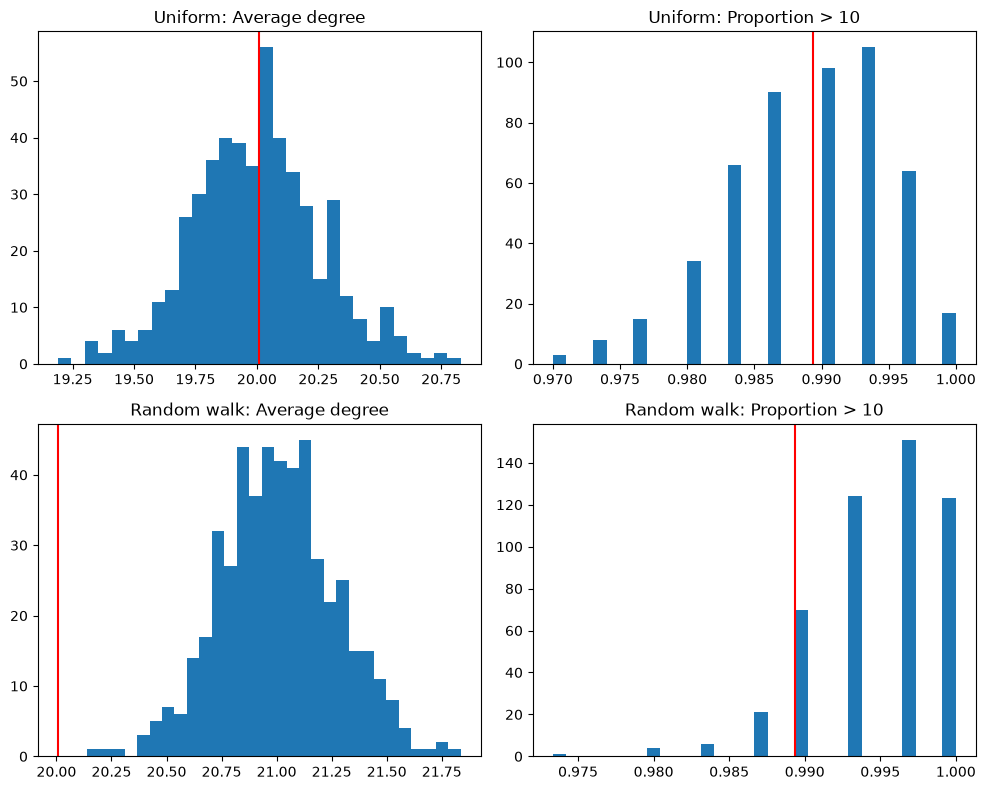

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
N, p = 20000, 0.001
n, n_reps = 300, 500

g = nx.fast_gnp_random_graph(N, p, seed=0)
deg = np.array([d for _, d in g.degree()])
nbrs = [list(g.neighbors(v)) for v in range(N)]

def estimators(nodes):
    d = deg[nodes]
    return d.mean(), (d > 10).mean()

theta = np.array([deg.mean(), (deg > 10).mean()])
print("True values: avg degree =", theta[0], "prop > 10 =", theta[1])

est_unif = np.array([estimators(rng.choice(N, n, replace=True)) for _ in range(n_reps)])

def random_walk():
    Y = np.empty(n, dtype=int)
    Y[0] = rng.integers(N)
    for i in range(1, n):
        nb = nbrs[Y[i - 1]]
        Y[i] = nb[rng.integers(len(nb))] if nb else Y[i - 1]
    return Y

est_rw = np.array([estimators(random_walk()) for _ in range(n_reps)])

names = ["Average degree", "Proportion > 10"]
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

for row, (method, est) in enumerate([("Uniform", est_unif), ("Random walk", est_rw)]):
    for col in range(2):
        ax[row, col].hist(est[:, col], bins=30)
        ax[row, col].axvline(theta[col], color="red")
        ax[row, col].set_title(f"{method}: {names[col]}")

    bias = est.mean(axis=0) - theta
    se = est.std(axis=0, ddof=1)
    print(method, "bias =", bias, "SE =", se)

plt.tight_layout()
plt.show()